# IND320 – Part 2: Data Sources


**Name:** Kristian Mathias Røhne
**Course:** IND320 – Data to Decision
**Hand-in:** Part 2 of 4
**Date:** 20.10.2026

## Links

- **GitHub repository:** https://github.com/kristianrohne/IND320_project_kristianrohne
- **Streamlit app:** https://ind320-project-kristianrohne.streamlit.app/
- **Screencast:** https://github.com/kristianrohne/IND320_project_kristianrohne/blob/part2/screencast/ASSIGNMENT_2_IND320_RECORDING__.mp4

## AI usage

I used Claude (Anthropic) as an assistant throughout this part of the project. It helped me with code for each part of the assignment, which I went through and added it to the files myself in small steps (often one function or a few lines at a time), so I could test and understand each change before moving on. I asked it to explain the code line by line, and I wrote the markdown comments in the notebook based on those explanations.

Claude helped me with:
- setting up Cassandra in Docker, Spark with the Cassandra connector, and MongoDB Atlas, using the course book's instructions;
- debugging errors (e.g. Spark failing to start, a misnamed secrets folder, and MongoDB blocking Streamlit Cloud's IP address);
- understanding the NVE and ENTSO-E APIs and choosing a data format for MongoDB;
- structuring the Streamlit pages (radio buttons, columns, pills, expander) and the notebook;
- drafting this text and the work log, which I then edited.

All code was run and checked by me, and I am responsible for the final content.

## Work log

I started part 2 by fixing the feedback from part 1. The reviewers pointed out that EL and VASS areas were mixed in the plots, since I only filtered on area number. I changed the data loader to filter on area type as well, added a short explanation of the area types in the app, and changed the overview table to use the first calendar month instead of the first four rows. I created a new branch, part2, so the reviewed version on main stays unchanged until the feedback round is finished.

Next, I set up the databases. Cassandra runs locally in Docker. The first attempt failed simply because Docker Desktop was not running. Spark needs Java, and my first Spark session failed with a "Java gateway exited" error until JAVA_HOME pointed to the Java 17 version installed on my Mac. A small test table confirmed that Spark could write to and read from Cassandra. For MongoDB I created a free Atlas cluster. The connection string is stored in .streamlit/secrets.toml, which is excluded from GitHub. My first attempt failed because I had named the folder "streamlit" without the dot.

I replaced the CSV file with NVE's Magasinstatistikk API. Since the API returns the same columns as the CSV, most of the cleaning code from part 1 could be reused. The area endpoint showed that the statistics cover all of Norway (NO), five electricity price areas (EL) and water-course areas (VASS). Interestingly, VASS 4 is listed but has no data. The API has no date parameters, so the app downloads everything once, caches it, and the month slider selects the interval shown.

In the Streamlit app, I replaced the area dropdown with radio buttons for area type, so the table and plot now show all areas of the chosen type at once: one LineChartColumn per area in the table, and one line per area in the plot, using pandas' pivot. I also added a new page with two columns: a pie chart of flows in and out of Norway for a chosen connection and year, and a line plot for months selected with pills. When deploying, the new page failed online because MongoDB Atlas only allowed my own IP address. Allowing access from anywhere (0.0.0.0/0) fixed this.

My ENTSO-E token had not arrived by the deadline, so I built the flows page using dummy data in the same format as the final data, and wrote the ENTSO-E → Cassandra → Spark → MongoDB code in advance, ready to run when the token arrives. ENTSO-E reports flows per border between price areas (e.g. NO2-DE), and the code aggregates the hourly flows to daily totals in Spark before storing them in MongoDB, to keep the app fast.

## 1. Setup

### 1.1 Cassandra connection

In [2]:
# Connect to the local Cassandra instance running in Docker
from cassandra.cluster import Cluster

# Describe where Cassandra is: my own machine, port 9042 with docker opened
cluster = Cluster(['localhost'], port=9042)

# Opens the connections and returns a session
session = cluster.connect()

# Create a keyspace for this project 
session.execute("""
    CREATE KEYSPACE IF NOT EXISTS ind320
    WITH REPLICATION = {'class': 'SimpleStrategy', 'replication_factor': 1};
""")

# From now on, table names refer to tables inside ind320
session.set_keyspace('ind320')
print("Connected to Cassandra")

Connected to Cassandra


Cassandra runs locally in a Docker container (`docker run --name my_cassandra -p 9042:9042 -d cassandra:latest`), listening on port 9042.
Here I connect to it from Python and create a keyspace called `ind320`, which will hold the tables for this project.
A keyspace is Cassandra's equivalent of a database. `SimpleStrategy` with replication factor 1 means the data is stored once, which is enough for a single local machine.

### 1.2 Spark session

In [15]:
# Environment variables Spark needs (Mac). Adjust JAVA_HOME if your path differs.
import os
#sets enviroment variables for this python session only
#spark reads them when it starts
#Where java is:
os.environ["JAVA_HOME"] = "/Library/Java/JavaVirtualMachines/temurin-17.jdk/Contents/Home"
# Which python spark should use
os.environ["PYSPARK_PYTHON"] = "python"
os.environ["PYSPARK_DRIVER_PYTHON"] = "python"
# Tells spark there´s no Hadoop installed, which silences a warning
os.environ["PYSPARK_HADOOP_VERSION"] = "without"

from pyspark.sql import SparkSession

# Start Spark and load the Cassandra connector (downloaded automatically the first time)
spark = (SparkSession.builder.appName("IND320") # starts building the Spark configuration, one .config(...) per setting:
         .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1") # the Cassandra connector to download
         .config("spark.cassandra.connection.host", "localhost") # where Cassandra is.
         .config("spark.cassandra.connection.port", "9042") # where Cassandra is.
         .getOrCreate())
print("Spark started")

Spark started


Spark needs Java, so `JAVA_HOME` points to my Java 17 installation (Temurin). The other variables tell Spark which Python to use and that no Hadoop installation is present.
The SparkSession loads the Spark–Cassandra connector, which is downloaded automatically the first time (the long log output above), and points it to the local Cassandra.

### 1.3 Test Spark–Cassandra

In [16]:
# Small test table to check that Spark and Cassandra works
session.execute("CREATE TABLE IF NOT EXISTS test_table (id int PRIMARY KEY, name text);")

import pandas as pd
test_df = pd.DataFrame({"id": [1, 2], "name": ["hello", "cassandra"]})

# Write to Cassandra through Spark
# Converts the pandas DataFrame to a Spark DataFrame.
spark.createDataFrame(test_df).write.format("org.apache.spark.sql.cassandra") \
    .options(table="test_table", keyspace="ind320").mode("append").save() # which table to write to.

# Read it back through Spark
spark.read.format("org.apache.spark.sql.cassandra") \
    .options(table="test_table", keyspace="ind320").load().show()

+---+---------+
| id|     name|
+---+---------+
|  2|cassandra|
|  1|    hello|
+---+---------+



A small test to check that Spark can both write to and read from Cassandra.
The table is created with CQL through the Cassandra session, while the data is written and read through Spark.
The output shows the two rows, so the connection works.

### 1.4 MongoDB connection

In [8]:
# Connect to MongoDB Atlas (cloud). The URI is read from .streamlit/secrets.toml,
# so the password is never written in the notebook or pushed to GitHub.
import tomllib
from pymongo import MongoClient

# read uri from toml file
with open("../.streamlit/secrets.toml", "rb") as f:
    mongo_uri = tomllib.load(f)["mongo"]["uri"]

# creates the connection object.
mongo_client = MongoClient(mongo_uri)
mongo_client.admin.command("ping")  # raises an error if the connection fails
print("Connected to MongoDB")

# Test: insert, read and delete a document
test_collection = mongo_client["ind320"]["test"]
test_collection.insert_one({"name": "test", "value": 1})
print(list(test_collection.find({}, {"_id": 0})))
_ = test_collection.delete_many({})  # _ = hides the long result object

Connected to MongoDB
[{'name': 'test', 'value': 1}]


MongoDB Atlas is a cloud database (free M0 cluster). It will store the cleaned data that the Streamlit app reads, since the online app cannot reach Cassandra on my own computer.
The connection string, which includes the password, is stored in `.streamlit/secrets.toml`. This file is listed in `.gitignore`, so the password is never pushed to GitHub. Streamlit reads the same file.
The test inserts one document, reads it back and deletes it again.

## 2. Magasinstatistikk API (NVE)
### 2.1 Fetch data from the API

In [9]:
# Fetch reservoir statistics directly from NVE's Magasinstatistikk API (replaces the CSV from part 1).
# The endpoint takes no parameters and returns all weekly data as JSON.
import requests
import pandas as pd

NVE_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

# sends an HTTP GET request (like opening the URL in a browser). It gives up after 60 seconds.
response = requests.get(f"{NVE_URL}/HentOffentligData", timeout=60)
response.raise_for_status() # stop with an error if the request failed
reservoirs = pd.DataFrame(response.json()) # a list of dicts becomes a table automatically. The keys become column names.

# Same English column names as in part 1
reservoirs = reservoirs.rename(columns={
    "dato_Id": "date", "omrType": "area_type", "omrnr": "area_number",
    "iso_aar": "iso_year", "iso_uke": "iso_week", "fyllingsgrad": "fill_ratio",
    "kapasitet_TWh": "capacity_twh", "fylling_TWh": "filling_twh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "fill_ratio_previous_week",
    "endring_fyllingsgrad": "fill_ratio_change",
})

# As in part 1: the rows are not sorted, so convert to datetime and sort by date
reservoirs["date"] = pd.to_datetime(reservoirs["date"])
reservoirs = reservoirs.sort_values("date")
reservoirs.head()

,date,area_type,area_number,iso_year,iso_week,fill_ratio,capacity_twh,filling_twh,next_publication_date,fill_ratio_previous_week,fill_ratio_change
3111,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
11344,1995-01-08,VASS,2,1995,1,0.608856,23.237715,14.148431,0001-01-01T00:00:00,0.744693,-0.135837
11170,1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,0001-01-01T00:00:00,0.661432,-0.094525
14499,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041
9678,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0001-01-01T00:00:00,0.752631,-0.144643


The CSV file from part 1 is replaced by a direct connection to NVE's Magasinstatistikk API.
The `HentOffentligData` endpoint takes no parameters and returns all weekly reservoir data as JSON, with the same columns as the CSV.
The cleaning steps are the same as in part 1: English column names, and conversion of the date to datetime followed by sorting, since the rows from the API are not in date order either.

### 2.2 Area types (EL, VASS, NO)

In [19]:
# The API also describes which areas exist (land = all of Norway, elspot = price areas, vassdrag = water courses)
# fetches the list of areas.
areas = requests.get(f"{NVE_URL}/HentOmråder", timeout=60).json()

# The response is a list. If it contains a single dict grouped by land/elspot/vassdrag,
# flatten it into one list of areas first.
if areas and "land" in areas[0]:
    areas = areas[0]["land"] + areas[0]["elspot"] + areas[0]["vassdrag"]

areas_df = pd.DataFrame(areas)

# Shows only the useful columns
display(areas_df[["omrType", "omrnr", "navn", "navn_langt"]])

# Count weekly rows per area: shows which areas actually have data (VASS 4 has none)
display(reservoirs.groupby(["area_type", "area_number"]).size())

,omrType,omrnr,navn,navn_langt
0,NO,0,Norge,Norge
1,EL,1,NO 1,Elspotområde 1
2,EL,2,NO 2,Elspotområde 2
3,EL,3,NO 3,Elspotområde 3
4,EL,4,NO 4,Elspotområde 4
5,EL,5,NO 5,Elspotområde 5
6,VASS,1,VASS1,Vassdragsområde 1
7,VASS,2,VASS2,Vassdragsområde 2
8,VASS,3,VASS3,Vassdragsområde 3
9,VASS,4,VASS4,Vassdragsområde 4


area_type  area_number
EL         1              1658
           2              1658
           3              1658
           4              1658
           5              1658
NO         0              1658
VASS       1              1658
           2              1658
           3              1658
dtype: int64

The `HentOmråder` endpoint describes the areas covered by the statistics:
- **NO 0**: all of Norway
- **EL 1–5**: electricity price areas (elspot areas NO1–NO5)
- **VASS 1–4**: water-course areas (vassdragsområder)

The API lists VASS 4, but the statistics only contain data for VASS 1–3 (see the row count per area below).
In part 1 I filtered only on area number, so EL 1 and VASS 1 were mixed together. From now on I filter on both area type and area number.

### 2.3 Recreated plots from part 1

array([[<Axes: xlabel='date'>, <Axes: xlabel='date'>],
       [<Axes: xlabel='date'>, <Axes: xlabel='date'>],
       [<Axes: xlabel='date'>, <Axes: xlabel='date'>]], dtype=object)

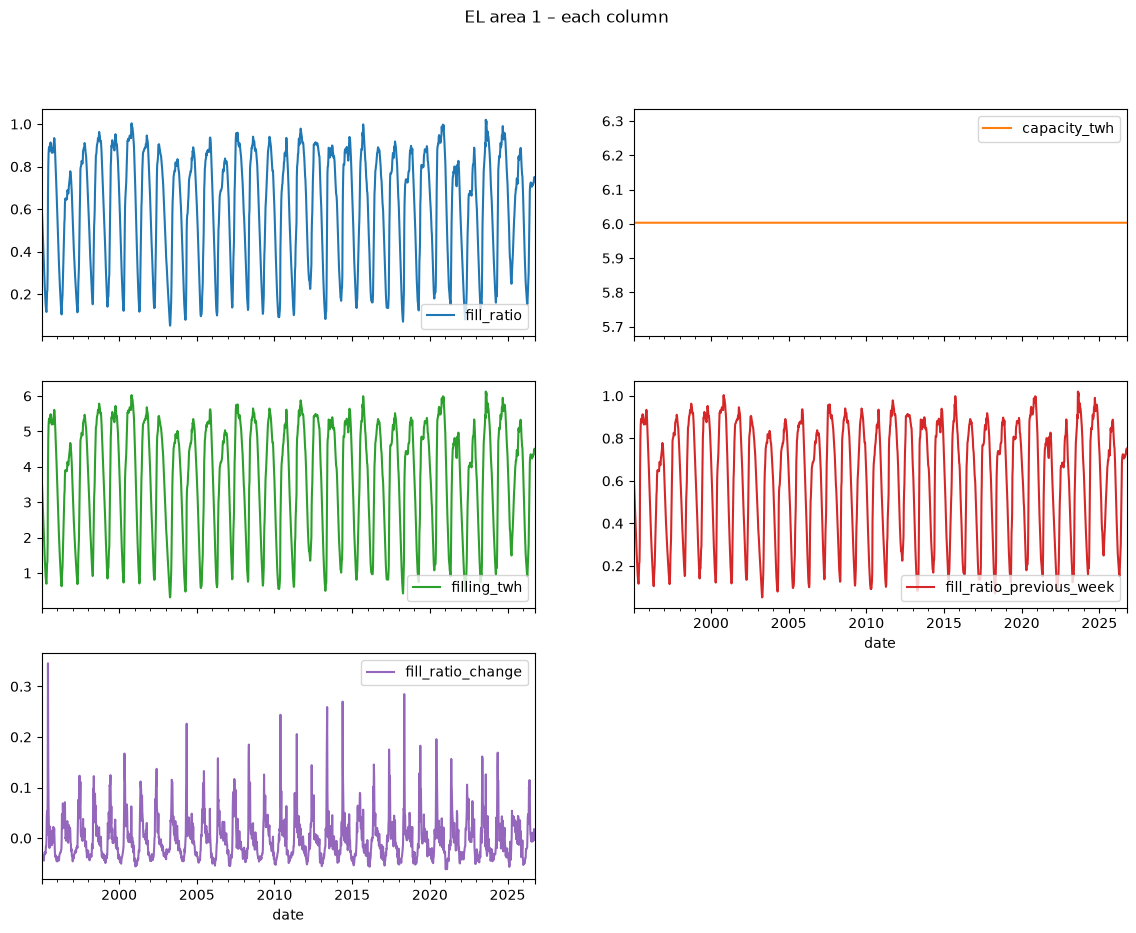

In [13]:
# Select one area (filter on BOTH type and number, otherwise EL 1 and VASS 1 get mixed)
area_df = reservoirs[(reservoirs["area_type"] == "EL") & (reservoirs["area_number"] == 1)]

# Plot each column separately for one area (as in part 1)
area_df = area_df.set_index("date")
cols_to_plot = ["fill_ratio", "capacity_twh", "filling_twh", "fill_ratio_previous_week", "fill_ratio_change"]
area_df[cols_to_plot].plot(subplots=True, layout=(3, 2), figsize=(14, 10), title="EL area 1 – each column")

<Axes: title={'center': 'EL area 1 – normalized columns'}, xlabel='date', ylabel='Normalized value (0–1)'>

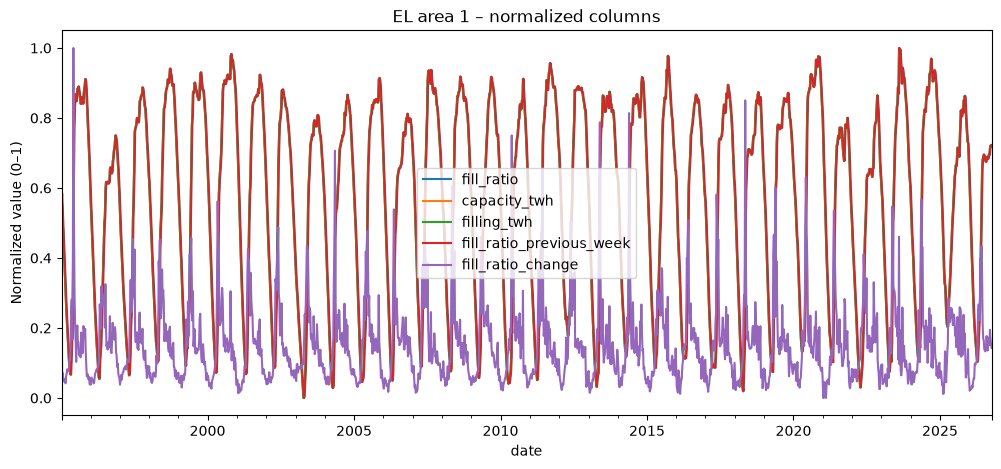

In [14]:
# All columns together, min-max normalized so they share one 0-1 scale (as in part 1)
normalized_df = (area_df[cols_to_plot] - area_df[cols_to_plot].min()) / (area_df[cols_to_plot].max() - area_df[cols_to_plot].min())
normalized_df.plot(figsize=(12, 5), title="EL area 1 – normalized columns", ylabel="Normalized value (0–1)")

The same plots as in part 1, now based on data from the API instead of the CSV file, and filtered on both area type and area number (EL area 1).
The separate plots show the yearly cycle of the reservoirs: they fill up in spring and summer when the snow melts, and empty during winter.
Capacity looks constant.
In the combined plot the columns are min-max normalized to 0–1, because they are on very different scales (ratios vs TWh).

## 3. ENTSO-E cross-border flows
### 3.1 Fetch data (last two years)

**Note:** At the time of delivery, I had not yet received my ENTSO-E security token, so the cells in sections 3.1–3.5 and 4 have been written but not run.
To be able to build and test the Streamlit page anyway, I inserted dummy data into MongoDB with the same format as the final data (see the last cell).
When the token arrives, I will run these cells, replace the dummy data with the real ENTSO-E data, and update the plots.

ENTSO-E reports cross-border flows per border between bidding zones (NO1–NO5 and the neighbouring zones in Sweden, Finland, Denmark, the Netherlands, Germany and the UK), rather than per country. The connections in the code are therefore named e.g. NO2-DE.

In [ ]:
# Fetch hourly cross-border physical flows to/from Norway from the ENTSO-E API (last two years).
# entsoe-py handles the API calls and turns the XML responses into pandas data.
from entsoe import EntsoePandasClient

# The token is stored in secrets.toml (not pushed to GitHub), like the MongoDB password
with open("../.streamlit/secrets.toml", "rb") as f:
    entsoe_token = tomllib.load(f)["entsoe"]["token"]
entsoe_client = EntsoePandasClient(api_key=entsoe_token)

# Time interval: the last two years up to today (ENTSO-E needs time-zone-aware timestamps)
end = pd.Timestamp.now(tz="Europe/Oslo").normalize()
start = end - pd.DateOffset(years=2)

# Borders between Norwegian price areas and neighbouring areas: (name, Norwegian area, other area)
BORDERS = [
    ("NO1-SE3", "NO_1", "SE_3"),
    ("NO3-SE2", "NO_3", "SE_2"),
    ("NO4-SE1", "NO_4", "SE_1"),
    ("NO4-SE2", "NO_4", "SE_2"),
    ("NO4-FI",  "NO_4", "FI"),
    ("NO2-DK1", "NO_2", "DK_1"),
    ("NO2-NL",  "NO_2", "NL"),
    ("NO2-DE",  "NO_2", "DE_LU"),
    ("NO2-GB",  "NO_2", "GB"),
]

frames = []
for connection, no_area, other_area in BORDERS:
    # Each border has two directions: out of Norway and into Norway
    for direction, area_from, area_to in [("out", no_area, other_area), ("in", other_area, no_area)]:
        try:
            flow = entsoe_client.query_crossborder_flows(area_from, area_to, start=start, end=end)
        except Exception as error:
            # Some borders may have no data (e.g. GB after Brexit); skip them instead of stopping
            print(f"No data for {area_from} -> {area_to}: {error}")
            continue
        frames.append(pd.DataFrame({
            "connection": connection,
            "direction": direction,
            # Convert to UTC without time zone, which Cassandra/Spark handle more easily
            "time": flow.index.tz_convert("UTC").tz_localize(None),
            "flow_mw": flow.values,
        }))
        print(f"{area_from} -> {area_to}: {len(flow)} rows")

# Combine all borders and directions into one long table
flows = pd.concat(frames, ignore_index=True)
flows.head()

### 3.2 Insert into Cassandra with Spark

In [ ]:
# Create a Cassandra table for the hourly flows.
# Partition key (connection, direction): all rows for one connection and direction are stored together.
# Clustering key time: rows within a partition are sorted by time, and each hour is unique.
session.execute("""
    CREATE TABLE IF NOT EXISTS crossborder_flows (
        connection text,
        direction  text,
        time       timestamp,
        flow_mw    double,
        PRIMARY KEY ((connection, direction), time)
    );
""")

# Make Spark treat timestamps as UTC, matching the data (otherwise it uses the Mac's local time zone)
spark.conf.set("spark.sql.session.timeZone", "UTC")

# Convert the pandas DataFrame to a Spark DataFrame and write it to Cassandra
spark.createDataFrame(flows).write.format("org.apache.spark.sql.cassandra") \
    .options(table="crossborder_flows", keyspace="ind320").mode("append").save()

# Check: count the rows in Cassandra
session.execute("SELECT COUNT(*) FROM crossborder_flows;").one()

### 3.3 Extract columns with Spark

In [ ]:
# Read the flows back from Cassandra with Spark and select only the relevant columns
from pyspark.sql import functions as F

flows_spark = spark.read.format("org.apache.spark.sql.cassandra") \
    .options(table="crossborder_flows", keyspace="ind320").load()

hourly_spark = flows_spark.select("connection", "direction", "time", "flow_mw")

# Hourly data as pandas, used for the line plot (first month)
hourly_df = hourly_spark.toPandas()

# Daily totals with Spark, used for the pie chart and MongoDB.
# flow_mw is the average power in an hour, so average MW over a day x 24 h = MWh for that day.
daily_spark = (hourly_spark
    .withColumn("date", F.to_date("time"))                 # timestamp -> date
    .groupBy("connection", "direction", "date")            # one group per connection, direction and day
    .agg((F.avg("flow_mw") * 24).alias("flow_mwh"))        # daily energy in MWh
    .orderBy("connection", "direction", "date"))

daily_df = daily_spark.toPandas()
daily_df["date"] = pd.to_datetime(daily_df["date"])        # Spark date -> pandas datetime
daily_df.head()

### 3.4 Pie chart – one year, one connection


In [ ]:
import matplotlib.pyplot as plt

# Choose connection and year (2025 is the only full year in the two-year interval)
pie_connection = "NO2-DE"
pie_year = 2025

pie_data = daily_df[(daily_df["connection"] == pie_connection) & (daily_df["date"].dt.year == pie_year)]

# Total flow out of and into Norway for the year
totals = pie_data.groupby("direction")["flow_mwh"].sum()
print((totals / 1e6).round(2).astype(str) + " TWh")  # 1 TWh = 1,000,000 MWh

totals.plot.pie(autopct="%1.0f%%", ylabel="", figsize=(5, 5),
                title=f"{pie_connection}, {pie_year}: flow out of and into Norway")
plt.show()

### 3.5 Line plot – first month, all connections and directions

In [ ]:
# First month of the chosen year, hourly values
month_df = hourly_df[(hourly_df["time"] >= f"{pie_year}-01-01") & (hourly_df["time"] < f"{pie_year}-02-01")].copy()

# One label per line, e.g. "NO2-DE out"
month_df["line"] = month_df["connection"] + " " + month_df["direction"]

# One column per connection+direction -> one line each
wide_df = month_df.pivot(index="time", columns="line", values="flow_mw")

wide_df.plot(figsize=(14, 6), title=f"Cross-border flows, January {pie_year}", ylabel="Flow (MW)", xlabel="Time")
plt.legend(ncol=3, fontsize="small")
plt.show()

## 4. Insert into MongoDB

In [ ]:
# Insert the Spark-aggregated daily data into MongoDB, where the Streamlit app reads it.
# Not run yet: waiting for the ENTSO-E token (see note in section 3). Will replace the dummy cell below.
flows_collection = mongo_client["ind320"]["crossborder_flows"]
flows_collection.delete_many({})                           # remove old/dummy data first
flows_collection.insert_many(daily_df.to_dict("records"))  # one dictionary per row
print("Documents in MongoDB:", flows_collection.count_documents({}))

In [20]:
# TEMPORARY: dummy data with the same format as the real ENTSO-E data will have,
# so the Streamlit page can be built before the ENTSO-E token arrives.
# This cell will be replaced by the real Spark-extracted data later.
import numpy as np

dates = pd.date_range("2024-10-01", "2026-09-30", freq="D")   # about two years, daily
connections = ["NO-SE", "NO-DK", "NO-FI", "NO-DE", "NO-NL", "NO-GB"]
rng = np.random.default_rng(42)  # fixed seed, so the dummy data is the same every run

dummy_rows = []
for connection in connections:
    for direction in ["out", "in"]:
        for date in dates:
            dummy_rows.append({
                "connection": connection,
                "direction": direction,
                "date": date,
                "flow_mwh": float(rng.uniform(0, 20000)),  # random daily flow in MWh
            })

flows_collection = mongo_client["ind320"]["crossborder_flows"]
flows_collection.delete_many({})          # empty the collection first, so reruns don't duplicate data
flows_collection.insert_many(dummy_rows)
print("Documents in MongoDB:", flows_collection.count_documents({}))

Documents in MongoDB: 8760
